# 06 · Avaliação (E2–E5)
**CRISP-DM:** Avaliação · **RQ1, RQ2, RQ3**

- **E2 · Detecção Normal/Residual:** método proposto versus baselines (z-score global, percentil global p1–p99, semana anterior) e variantes de contexto; métricas por janela (precisão, recall, F1, PR-AUC), por episódio (recall, precisão, F1; cada episódio conta uma vez; sequências residuais só em janelas limpas contam como falso alarme) e taxa de alarmes em janelas limpas; análise do feriado; curva de operação.
- **E3 · Consulta pré-incidente:** para cada episódio, um incidente é registrado num instante sorteado dentro dele e o método analisa as 6 h anteriores. Consultas de controle em períodos limpos. Métricas: sensibilidade, especificidade, erro no início estimado, acurácia do lado provável.
- **E4 · Atributos relevantes:** frequência com que cada atributo passa do seu limite no recurso nas janelas residuais de cada tipo de falha.
- **E5 · Sensibilidade à janela:** repetição com 15 min, 30 min, 1 h e 4 h.

Resultados: média ± desvio-padrão nas 10 sementes.

In [1]:
%run ./00_funcoes.ipynb

00_funcoes carregado · raiz: /home/wsl/gh/mestrado/claude9


In [2]:
import pickle
with open(RESULTADOS / "04_modelos.pkl", "rb") as f:
    ajustados = pickle.load(f)
episodios_todos = pd.read_csv(RESULTADOS / "05_episodios.csv", parse_dates=["inicio", "fim"])
lim_teste = pd.read_csv(RESULTADOS / "05_limites_teste.csv", index_col=0, parse_dates=["inicio", "fim"])
jan_limpo = adicionar_tipo_dia_adaptado(pd.read_parquet(RESULTADOS / f"02_janelas_{JANELA}.parquet"))
poucos = recursos_poucos_clientes(recortar(jan_limpo, TREINO))
NOMES_METODOS = list(ajustados)
PRINCIPAIS = [PROPOSTO] + BASELINES

## Execução por semente

In [3]:
def avaliar_semente(js, eps, ajustados, janela, semente, consultas_metodos):
    js = js.reset_index(drop=True)
    teste = ((js["janela"] >= TESTE[0]) & (js["janela"] < TESTE[1])).to_numpy()
    jt = js[teste]
    perfil = ajustados[PROPOSTO]["modelo"]
    zs = perfil.z(js)
    zn = normalizado(ajustados[PROPOSTO], js)
    met, det, cons, escores = [], [], [], {}
    for nome, a in ajustados.items():
        esc = pontuar_metodo(a, js, js)
        escores[nome] = esc
        m, d, _ = avaliar_deteccao(jt, esc[teste], a["tau"], eps)
        met.append(dict(metodo=nome, semente=semente, **m))
        det.append(d.assign(metodo=nome, semente=semente))
        if nome in consultas_metodos:
            residual = (esc > a["tau"].reindex(js["recurso"]).to_numpy()).to_numpy()
            c = consultas(js, residual, zs, zn, eps, lim_teste, janela, poucos, semente)
            cons.append(c.assign(metodo=nome, semente=semente))
    return pd.DataFrame(met), pd.concat(det), pd.concat(cons), escores, zn


metricas, deteccoes, consultas_df, escores_sem, zd_sem, series = [], [], [], {}, {}, {}
for s in SEMENTES:
    js = pd.read_parquet(RESULTADOS / "05_series" / f"serie_{JANELA}_s{s}.parquet")
    js = adicionar_tipo_dia_adaptado(js).reset_index(drop=True)
    eps = episodios_todos[episodios_todos["semente"] == s].drop(columns="semente")
    m, d, c, e, z = avaliar_semente(js, eps, ajustados, JANELA, s, NOMES_METODOS)
    metricas.append(m); deteccoes.append(d); consultas_df.append(c)
    escores_sem[s], zd_sem[s], series[s] = e, z, js
metricas = pd.concat(metricas, ignore_index=True)
deteccoes = pd.concat(deteccoes, ignore_index=True)
consultas_df = pd.concat(consultas_df, ignore_index=True)
print("ok:", len(metricas), "linhas de métricas")

ok: 80 linhas de métricas


## E2 · Detecção: resumo por método

In [4]:
COLS = ["precisao_jan", "recall_jan", "f1_jan", "pr_auc_jan", "alarmes_limpas", "recall_ep", "precisao_ep", "f1_ep",
        "atraso_mediano_h"]
media = metricas.groupby("metodo")[COLS].mean().loc[NOMES_METODOS]
desvio = metricas.groupby("metodo")[COLS].std().loc[NOMES_METODOS]
resumo = media.round(3).astype(str) + " ± " + desvio.round(3).astype(str)
resumo

,precisao_jan,recall_jan,f1_jan,pr_auc_jan,alarmes_limpas,recall_ep,precisao_ep,f1_ep,atraso_mediano_h
metodo,,,,,,,,,
Perfil contextual (proposto),0.783 ± 0.046,0.226 ± 0.035,0.35 ± 0.045,0.397 ± 0.043,0.006 ± 0.001,0.3 ± 0.05,0.661 ± 0.063,0.412 ± 0.058,0.0 ± 0.0
Perfil 3 tipos de dia,0.661 ± 0.057,0.23 ± 0.037,0.341 ± 0.047,0.366 ± 0.042,0.012 ± 0.001,0.314 ± 0.046,0.489 ± 0.046,0.382 ± 0.048,0.05 ± 0.158
Perfil 2 tipos de dia,0.817 ± 0.046,0.223 ± 0.034,0.35 ± 0.045,0.402 ± 0.041,0.005 ± 0.001,0.286 ± 0.052,0.682 ± 0.066,0.402 ± 0.061,0.0 ± 0.0
Perfil só hora,0.811 ± 0.041,0.223 ± 0.028,0.349 ± 0.038,0.401 ± 0.031,0.005 ± 0.001,0.3 ± 0.049,0.688 ± 0.075,0.417 ± 0.061,0.0 ± 0.0
Perfil sem feriado,0.782 ± 0.048,0.224 ± 0.036,0.348 ± 0.047,0.392 ± 0.043,0.006 ± 0.001,0.3 ± 0.05,0.661 ± 0.063,0.412 ± 0.058,0.0 ± 0.0
z-score global,0.813 ± 0.032,0.226 ± 0.022,0.353 ± 0.029,0.401 ± 0.033,0.005 ± 0.0,0.27 ± 0.035,0.664 ± 0.051,0.384 ± 0.042,0.0 ± 0.0
Percentil global p1–p99,0.645 ± 0.055,0.205 ± 0.032,0.31 ± 0.042,0.332 ± 0.034,0.011 ± 0.001,0.245 ± 0.046,0.497 ± 0.068,0.328 ± 0.057,0.0 ± 0.0
Semana anterior,0.798 ± 0.033,0.227 ± 0.016,0.353 ± 0.021,0.395 ± 0.031,0.006 ± 0.001,0.264 ± 0.031,0.663 ± 0.066,0.377 ± 0.04,0.0 ± 0.0


### Comparação pareada (por semente) do F1 por episódio: proposto versus cada método

In [5]:
piv = metricas.pivot(index="semente", columns="metodo", values="f1_ep")
comp = pd.DataFrame({
    "Δ F1 médio (proposto − método)": (piv[PROPOSTO].to_numpy()[:, None] - piv.to_numpy()).mean(axis=0),
    "sementes em que o proposto é melhor": (piv[PROPOSTO].to_numpy()[:, None] > piv.to_numpy()).sum(axis=0),
    "p (Wilcoxon pareado)": [np.nan if c == PROPOSTO else stats.wilcoxon(piv[PROPOSTO], piv[c]).pvalue for c in piv.columns],
}, index=piv.columns).loc[NOMES_METODOS]
comp.round(4)

/home/wsl/.pyenv/versions/3.11.9/lib/python3.11/site-packages/scipy/stats/_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


,Δ F1 médio (proposto − método),sementes em que o proposto é melhor,p (Wilcoxon pareado)
metodo,,,
Perfil contextual (proposto),0.0000,0,NaN
Perfil 3 tipos de dia,0.0300,8,0.0098
Perfil 2 tipos de dia,0.0095,6,0.0840
Perfil só hora,-0.0054,2,0.2324
Perfil sem feriado,0.0000,0,1.0000
z-score global,0.0281,7,0.1602
Percentil global p1–p99,0.0836,9,0.0059
Semana anterior,0.0350,8,0.0371


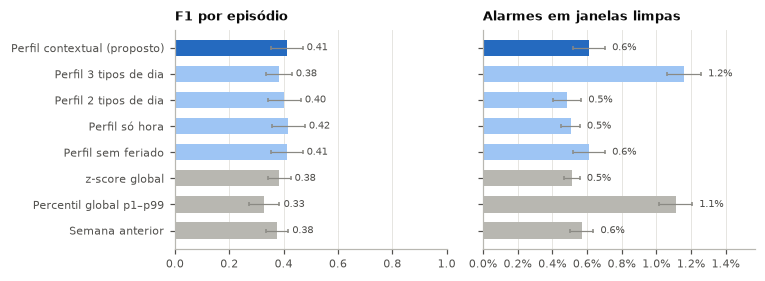

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6), sharey=True)
ordem = NOMES_METODOS[::-1]
cores = [AZUL[4] if m == PROPOSTO else (AZUL[1] if m.startswith("Perfil") else CINZA) for m in ordem]
for ax, col, titulo, fmt in [(axes[0], "f1_ep", "F1 por episódio", "{:.2f}"),
                             (axes[1], "alarmes_limpas", "Alarmes em janelas limpas", "{:.1%}")]:
    y = np.arange(len(ordem))
    ax.barh(y, media.loc[ordem, col], xerr=desvio.loc[ordem, col], color=cores, height=0.62,
            error_kw=dict(ecolor=TXT3, lw=0.8, capsize=1.5))
    for yi, v, d in zip(y, media.loc[ordem, col], desvio.loc[ordem, col]):
        ax.text(v + d + (0.015 if col == "f1_ep" else 0.0004), yi, fmt.format(v), va="center", fontsize=6.5, color=TXT2)
    ax.set_title(titulo, loc="left")
    ax.grid(axis="y", visible=False)
    ax.set_yticks(y)
    ax.set_yticklabels(ordem)
axes[1].xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=1))
axes[1].set_xlim(0, media["alarmes_limpas"].max() * 1.35)
axes[0].set_xlim(0, 1)
fig.tight_layout()
salvar(fig, "fig_metodos")
plt.show()

### Recall por tipo de falha e intensidade

In [7]:
det = deteccoes[deteccoes["avaliavel"]]
rec_ti = det.groupby(["metodo", "tipo", "intensidade"])["detectado"].mean().unstack()[INTENSIDADES]
rec_prop = rec_ti.loc[PROPOSTO]
rec_prop.index = rec_prop.index.map(NOMES_TIPO)
display(rec_prop.round(2))
rec_tipo = det.groupby(["tipo", "metodo"])["detectado"].mean().unstack()[PRINCIPAIS]
rec_tipo.index = rec_tipo.index.map(NOMES_TIPO)
rec_tipo.round(2)

intensidade,baixa,media,alta
tipo,,,
4xx de 1 cliente,0.34,0.48,0.41
Pico de 5xx,0.63,0.66,0.83
Latência elevada,0.10,0.31,0.41
Queda de volume,0.03,0.00,0.10
Rajada de 1 cliente,0.03,0.03,0.13


metodo,Perfil contextual (proposto),z-score global,Percentil global p1–p99,Semana anterior
tipo,,,,
4xx de 1 cliente,0.41,0.33,0.33,0.34
Pico de 5xx,0.71,0.72,0.64,0.72
Latência elevada,0.27,0.27,0.19,0.22
Queda de volume,0.04,0.02,0.02,0.04
Rajada de 1 cliente,0.07,0.01,0.04,0.00


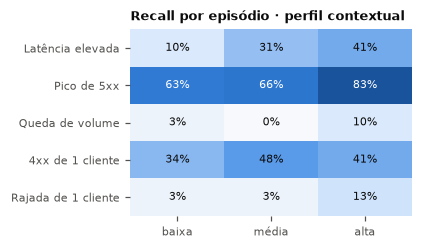

In [8]:
fig, ax = plt.subplots(figsize=(3.3, 2.2))
v = rec_prop.loc[[NOMES_TIPO[t] for t in TIPOS]]
ax.imshow(v.to_numpy(), cmap=CMAP_SEQ, vmin=0, vmax=1, aspect="auto")
for i in range(v.shape[0]):
    for j in range(v.shape[1]):
        x = v.iat[i, j]
        ax.text(j, i, f"{x:.0%}", ha="center", va="center", fontsize=7, color="white" if x > 0.6 else TXT1)
ax.set_xticks(range(3))
ax.set_xticklabels(["baixa", "média", "alta"])
ax.set_yticks(range(len(v)))
ax.set_yticklabels(v.index)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title("Recall por episódio · perfil contextual", loc="left")
salvar(fig, "fig_recall_tipo_intensidade")
plt.show()

### Recall por recurso (método proposto)
Recursos com τ alto (picos reais frequentes em agosto) detectam menos.

In [9]:
taus = pd.DataFrame({n: a["tau"] for n, a in ajustados.items()})
rec_rec = det[det["metodo"] == PROPOSTO].groupby("recurso")["detectado"].agg(["mean", "size"])
rec_rec["tau"] = taus[PROPOSTO]
rec_rec.columns = ["recall_ep", "episodios", "tau"]
rec_rec.round(2)

,recall_ep,episodios,tau
recurso,,,
14553746,0.28,50,2.17
17834257,0.12,50,1.35
18139260,0.26,50,2.05
18166630,0.38,50,3.27
18168196,0.52,50,1.82
18169917,0.40,50,1.62
18170306,0.22,50,2.25
18344302,0.26,50,1.72
18917905,0.10,10,1.86


### Feriado (07/09): alarmes em janelas limpas

In [10]:
fer = []
for s in SEMENTES:
    js = series[s]
    dia = (js["janela"].dt.normalize() == pd.Timestamp("2026-09-07")) & (js["episodio"] == -1)
    for nome in NOMES_METODOS:
        tau = ajustados[nome]["tau"].reindex(js["recurso"]).to_numpy()
        fer.append(dict(metodo=nome, semente=s, alarmes_feriado=(escores_sem[s][nome] > tau)[dia].mean()))
feriado = pd.DataFrame(fer).groupby("metodo")["alarmes_feriado"].mean().loc[NOMES_METODOS]
feriado.round(4)

metodo
Perfil contextual (proposto)    0.0000
Perfil 3 tipos de dia           0.0265
Perfil 2 tipos de dia           0.0000
Perfil só hora                  0.0000
Perfil sem feriado              0.0000
z-score global                  0.0000
Percentil global p1–p99         0.0074
Semana anterior                 0.0000
Name: alarmes_feriado, dtype: float64

### Curva de operação: recall por episódio × alarmes em janelas limpas
A meta de alarmes da calibração varia de 0,2% a 10%. Cada ponto é a média nas 10 sementes.

In [11]:
METAS = [0.002, 0.005, 0.01, 0.02, 0.05, 0.10]
curva = []
for nome in PRINCIPAIS:
    a = ajustados[nome]
    for meta in METAS:
        tau = calibrar_tau(a["escores_cal"], a["recursos_cal"], meta)
        for s in SEMENTES:
            js = series[s]
            teste = ((js["janela"] >= TESTE[0]) & (js["janela"] < TESTE[1])).to_numpy()
            eps = episodios_todos[episodios_todos["semente"] == s]
            m, _, _ = avaliar_deteccao(js[teste], escores_sem[s][nome][teste], tau, eps)
            curva.append(dict(metodo=nome, meta=meta, semente=s, **m))
curva = pd.DataFrame(curva).groupby(["metodo", "meta"])[["recall_ep", "alarmes_limpas", "f1_ep"]].mean().reset_index()
curva.round(3)

,metodo,meta,recall_ep,alarmes_limpas,f1_ep
0,Percentil global p1–p99,0.002,0.102,0.001,0.179
1,Percentil global p1–p99,0.005,0.182,0.003,0.288
2,Percentil global p1–p99,0.010,0.245,0.011,0.328
3,Percentil global p1–p99,0.020,0.361,0.030,0.357
4,Percentil global p1–p99,0.050,0.448,0.050,0.354
5,Percentil global p1–p99,0.100,0.475,0.066,0.333
6,Perfil contextual (proposto),0.002,0.116,0.000,0.203
7,Perfil contextual (proposto),0.005,0.250,0.003,0.375
8,Perfil contextual (proposto),0.010,0.300,0.006,0.412
9,Perfil contextual (proposto),0.020,0.393,0.019,0.408


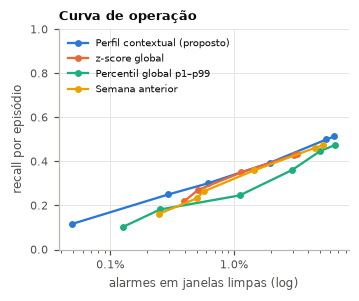

In [12]:
fig, ax = plt.subplots(figsize=(3.4, 2.6))
for i, nome in enumerate(PRINCIPAIS):
    c = curva[(curva["metodo"] == nome) & (curva["alarmes_limpas"] > 0)]  # 0% não cabe na escala log
    ax.plot(c["alarmes_limpas"], c["recall_ep"], marker="o", ms=3.5, color=CORES[i], lw=1.5, label=nome)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=1))
ax.set_xlabel("alarmes em janelas limpas (log)")
ax.set_ylabel("recall por episódio")
ax.set_ylim(0, 1)
ax.legend(loc="upper left", fontsize=6.5)
ax.set_title("Curva de operação", loc="left")
salvar(fig, "fig_curva_operacao")
plt.show()

## E3 · Consulta pré-incidente (6 h antes do registro)

In [13]:
def resumo_consultas(c):
    inc, ctl = c[c["tipo"] == "incidente"], c[c["tipo"] == "controle"]
    res = inc[inc["estado"] == "Residual"]
    det_lado = res[res["lado_pred"] != "indeterminado"]
    return pd.Series(dict(
        sensibilidade=(inc["estado"] == "Residual").mean(),
        especificidade=(ctl["estado"] == "Normal").mean(),
        erro_inicio_mediano_h=res["erro_inicio_h"].abs().median(),
        inicio_ate_1_janela=(res["erro_inicio_h"].abs() <= 1).mean(),
        inicio_antecipado=(res["erro_inicio_h"] < 0).mean(),
        cobertura_lado=(res["lado_pred"] != "indeterminado").mean(),
        acuracia_lado=(det_lado["lado_pred"] == det_lado["lado_real"]).mean(),
        acuracia_lado_com_indeterminado=(res["lado_pred"] == res["lado_real"]).mean(),
    ))


cons_res = consultas_df.groupby(["metodo", "semente"]).apply(resumo_consultas)
cons_media = cons_res.groupby("metodo").mean().loc[NOMES_METODOS]
cons_desvio = cons_res.groupby("metodo").std().loc[NOMES_METODOS]
(cons_media.round(3).astype(str) + " ± " + cons_desvio.round(3).astype(str))

,sensibilidade,especificidade,erro_inicio_mediano_h,inicio_ate_1_janela,inicio_antecipado,cobertura_lado,acuracia_lado,acuracia_lado_com_indeterminado
metodo,,,,,,,,
Perfil contextual (proposto),0.277 ± 0.055,0.98 ± 0.023,0.1 ± 0.316,0.882 ± 0.109,0.042 ± 0.062,1.0 ± 0.0,0.928 ± 0.062,0.928 ± 0.062
Perfil 3 tipos de dia,0.298 ± 0.05,0.941 ± 0.031,0.1 ± 0.316,0.862 ± 0.112,0.103 ± 0.069,0.944 ± 0.041,0.921 ± 0.056,0.869 ± 0.05
Perfil 2 tipos de dia,0.266 ± 0.058,0.98 ± 0.023,0.0 ± 0.0,0.915 ± 0.063,0.027 ± 0.045,1.0 ± 0.0,0.942 ± 0.057,0.942 ± 0.057
Perfil só hora,0.277 ± 0.053,0.977 ± 0.026,0.1 ± 0.316,0.899 ± 0.074,0.033 ± 0.044,0.993 ± 0.023,0.939 ± 0.058,0.932 ± 0.054
Perfil sem feriado,0.277 ± 0.055,0.98 ± 0.023,0.1 ± 0.316,0.897 ± 0.115,0.042 ± 0.062,1.0 ± 0.0,0.928 ± 0.062,0.928 ± 0.062
z-score global,0.27 ± 0.043,0.975 ± 0.029,0.0 ± 0.0,0.883 ± 0.072,0.051 ± 0.06,0.954 ± 0.066,0.939 ± 0.055,0.896 ± 0.088
Percentil global p1–p99,0.241 ± 0.05,0.968 ± 0.022,0.0 ± 0.0,0.906 ± 0.067,0.108 ± 0.106,0.905 ± 0.093,0.91 ± 0.069,0.823 ± 0.097
Semana anterior,0.25 ± 0.034,0.977 ± 0.026,0.0 ± 0.0,0.937 ± 0.081,0.038 ± 0.049,1.0 ± 0.0,0.945 ± 0.049,0.945 ± 0.049


### Lado provável por tipo de falha (método proposto)

In [14]:
cp = consultas_df[(consultas_df["metodo"] == PROPOSTO) & (consultas_df["tipo"] == "incidente") & (consultas_df["estado"] == "Residual")]
lado_tipo = pd.crosstab(cp["tipo_falha"].map(NOMES_TIPO), cp["lado_pred"], normalize="index").round(2)
display(lado_tipo)
regras = pd.crosstab(cp["tipo_falha"].map(NOMES_TIPO), cp["regra"])
regras

lado_pred,consumidor,provedor
tipo_falha,,
4xx de 1 cliente,0.88,0.12
Latência elevada,0.00,1.00
Pico de 5xx,0.06,0.94
Queda de volume,0.00,1.00
Rajada de 1 cliente,0.75,0.25


regra,4xx elevado e concentrado em até 2 clientes,5xx elevado e concentrado em até 2 clientes,5xx elevado e espalhado entre clientes,aumento de volume concentrado no maior cliente,latência 2xx elevada,queda de volume
tipo_falha,,,,,,
4xx de 1 cliente,29,0,1,0,3,0
Latência elevada,0,0,2,0,19,0
Pico de 5xx,0,4,58,0,0,0
Queda de volume,0,0,1,0,0,1
Rajada de 1 cliente,0,0,1,3,0,0


## E4 · Atributos que disparam o Residual, por tipo de falha (método proposto)
Fração das janelas residuais de cada tipo de falha em que o atributo passou do seu limite no recurso (escore normalizado > 1).

In [15]:
linhas = []
for s in SEMENTES:
    js, zd = series[s], zd_sem[s]
    tau = ajustados[PROPOSTO]["tau"].reindex(js["recurso"]).to_numpy()
    res = (escores_sem[s][PROPOSTO] > tau).to_numpy()
    eps = episodios_todos[episodios_todos["semente"] == s].set_index("episodio")
    m = (js["episodio"] >= 0).to_numpy() & res
    sub = (zd[m] > 1).assign(tipo=eps.loc[js.loc[m, "episodio"], "tipo"].to_numpy())
    linhas.append(sub)
e4 = pd.concat(linhas).groupby("tipo")[ATRIBUTOS].mean()
e4.index = e4.index.map(NOMES_TIPO)
e4.columns = [NOMES[a] for a in e4.columns]
e4.round(2)

,volume,taxa 4xx,taxa 5xx,latência 2xx,nº de clientes,part. maior cliente,frac. clientes c/ 4xx,frac. clientes c/ 5xx
tipo,,,,,,,,
4xx de 1 cliente,0.02,0.97,0.00,0.05,0.00,0.05,0.11,0.00
Pico de 5xx,0.00,0.00,0.98,0.03,0.00,0.00,0.01,0.97
Latência elevada,0.00,0.00,0.00,0.98,0.00,0.00,0.02,0.02
Queda de volume,0.62,0.00,0.25,0.00,0.00,0.00,0.25,0.25
Rajada de 1 cliente,0.71,0.00,0.00,0.00,0.14,0.86,0.00,0.14


In [16]:
# Atributos em janelas residuais reais (sem injeção) no teste, para comparação
limpas = []
for s in SEMENTES[:1]:
    js, zd = series[s], zd_sem[s]
    tau = ajustados[PROPOSTO]["tau"].reindex(js["recurso"]).to_numpy()
    teste = ((js["janela"] >= TESTE[0]) & (js["janela"] < TESTE[1])).to_numpy()
    m = teste & (js["episodio"] == -1).to_numpy() & (escores_sem[s][PROPOSTO] > tau).to_numpy()
    limpas.append((zd[m] > 1).mean())
e4_real = pd.concat(limpas, axis=1).mean(axis=1)
e4_real.index = [NOMES[a] for a in e4_real.index]
e4.loc["Residual real (sem injeção)"] = e4_real
e4.round(2)

,volume,taxa 4xx,taxa 5xx,latência 2xx,nº de clientes,part. maior cliente,frac. clientes c/ 4xx,frac. clientes c/ 5xx
tipo,,,,,,,,
4xx de 1 cliente,0.02,0.97,0.00,0.05,0.00,0.05,0.11,0.00
Pico de 5xx,0.00,0.00,0.98,0.03,0.00,0.00,0.01,0.97
Latência elevada,0.00,0.00,0.00,0.98,0.00,0.00,0.02,0.02
Queda de volume,0.62,0.00,0.25,0.00,0.00,0.00,0.25,0.25
Rajada de 1 cliente,0.71,0.00,0.00,0.00,0.14,0.86,0.00,0.14
Residual real (sem injeção),0.30,0.00,0.10,0.40,0.00,0.00,0.00,0.50


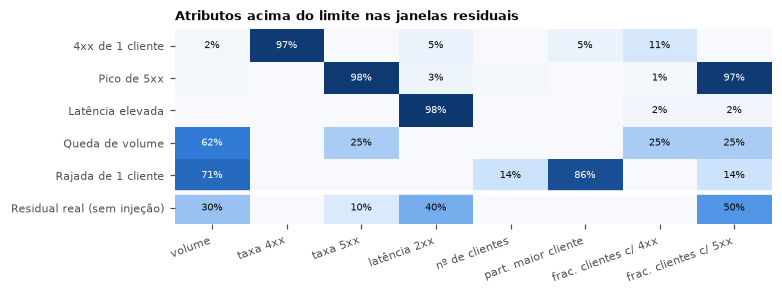

In [17]:
fig, ax = plt.subplots(figsize=(7.0, 2.3))
v = e4
ax.imshow(v.to_numpy(), cmap=CMAP_SEQ, vmin=0, vmax=1, aspect="auto")
for i in range(v.shape[0]):
    for j in range(v.shape[1]):
        x = v.iat[i, j]
        if x >= 0.005:
            ax.text(j, i, f"{x:.0%}", ha="center", va="center", fontsize=6.5, color="white" if x > 0.6 else TXT1)
ax.set_xticks(range(v.shape[1]))
ax.set_xticklabels(v.columns, rotation=20, ha="right")
ax.set_yticks(range(v.shape[0]))
ax.set_yticklabels(v.index)
ax.axhline(len(v) - 1.5, color="white", lw=3)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title("Atributos acima do limite nas janelas residuais", loc="left")
salvar(fig, "fig_atributos")
plt.show()

## Exemplo de episódio (semente 0)

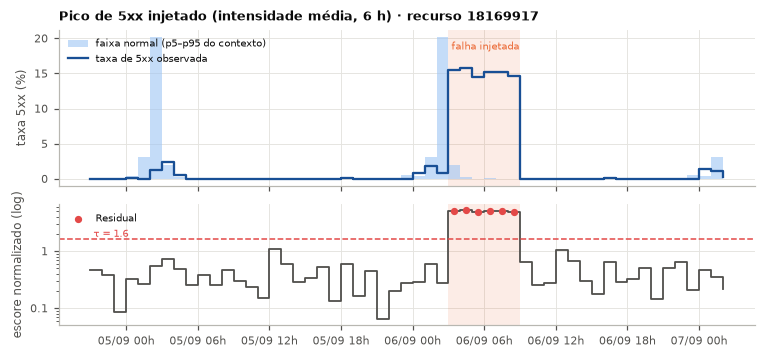

In [18]:
js0 = series[0]
eps0 = episodios_todos[episodios_todos["semente"] == 0]
cand = eps0[(eps0["tipo"] == "erro_5xx_provedor") & (eps0["duracao_h"] >= 3) & (~eps0["recurso"].isin(poucos))]
ep = cand.sort_values("intensidade", key=lambda s: s.map({"media": 0, "alta": 1, "baixa": 2})).iloc[0]
r = ep["recurso"]
w = js0[(js0["recurso"] == r) & (js0["janela"] >= ep["inicio"] - pd.Timedelta("30h")) &
        (js0["janela"] < ep["fim"] + pd.Timedelta("18h"))]
perfil = ajustados[PROPOSTO]["modelo"]
med, _, q05, q95 = perfil.referencia(w)
tau_r = ajustados[PROPOSTO]["tau"][r]
esc_w = escores_sem[0][PROPOSTO].loc[w.index]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.0, 3.3), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
for ax in (a1, a2):
    ax.axvspan(ep["inicio"], ep["fim"], color=CORES[1], alpha=0.12, lw=0)
a1.fill_between(w["janela"], q05["tx_5xx"] * 100, q95["tx_5xx"] * 100, step="post", color=AZUL[1], alpha=0.6, lw=0,
                label="faixa normal (p5–p95 do contexto)")
a1.step(w["janela"], w["tx_5xx"] * 100, where="post", color=AZUL[5], lw=1.5, label="taxa de 5xx observada")
a1.set_ylabel("taxa 5xx (%)")
a1.legend(loc="upper left", fontsize=6.5)
a1.set_title(f"Pico de 5xx injetado (intensidade {ep['intensidade'].replace('media', 'média')}, {ep['duracao_h']} h) · recurso {r}", loc="left")
a1.text(ep["inicio"], a1.get_ylim()[1] * 0.92, " falha injetada", color=CORES[1], fontsize=6.5, va="top")
esc_plot = esc_w.clip(lower=0.05)
a2.step(w["janela"], esc_plot, where="post", color=TXT2, lw=1.2)
res_w = esc_w > tau_r
a2.scatter(w["janela"][res_w] + pd.Timedelta("30min"), esc_plot[res_w], s=14, color=CORES[7], zorder=3, label="Residual")
a2.axhline(tau_r, color=CORES[7], lw=1, ls="--")
a2.text(w["janela"].iloc[0], tau_r, f" τ = {tau_r:.1f}", color=CORES[7], fontsize=6.5, va="bottom")
a2.set_yscale("log")
a2.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
a2.set_ylabel("escore normalizado (log)")
a2.legend(loc="upper left", fontsize=6.5)
a2.xaxis.set_major_formatter(mpl.dates.DateFormatter("%d/%m %Hh"))
fig.tight_layout()
salvar(fig, "fig_exemplo_episodio")
plt.show()

## Residual em janelas limpas do teste (candidatos a anomalias reais)
Sequências residuais do método proposto em janelas sem falha injetada (semente 0), inclusive no feriado.

In [19]:
tau = ajustados[PROPOSTO]["tau"].reindex(js0["recurso"]).to_numpy()
teste = ((js0["janela"] >= TESTE[0]) & (js0["janela"] < TESTE[1])).to_numpy()
res0 = (escores_sem[0][PROPOSTO] > tau).to_numpy() & teste
seq0 = sequencias(res0, js0["recurso"])
zd0 = zd_sem[0]
reais = []
for s_id in np.unique(seq0[seq0 >= 0]):
    idx = np.flatnonzero(seq0 == s_id)
    if (js0["episodio"].to_numpy()[idx] != -1).any():
        continue
    top = idx[np.argmax(escores_sem[0][PROPOSTO].to_numpy()[idx])]
    reais.append(dict(recurso=js0.loc[top, "recurso"], inicio=js0.loc[idx[0], "janela"], janelas=len(idx),
                      atributo=NOMES[zd0.iloc[top].idxmax()], escore=round(float(zd0.iloc[top].max()), 2)))
reais = pd.DataFrame(reais)
reais

,recurso,inicio,janelas,atributo,escore
0,17834257,2026-09-05 10:00:00,1,latência 2xx,1.58
1,18166630,2026-09-04 15:00:00,1,volume,4.04
2,18168196,2026-09-05 07:00:00,1,frac. clientes c/ 5xx,2.40
3,18169917,2026-09-01 03:00:00,2,latência 2xx,2.95
4,18170306,2026-09-05 00:00:00,2,volume,3.16
5,18344302,2026-09-05 00:00:00,1,frac. clientes c/ 5xx,2.15
6,18344302,2026-09-05 17:00:00,1,frac. clientes c/ 5xx,1.80
7,18917906,2026-09-02 01:00:00,1,frac. clientes c/ 5xx,5.48


## E5 · Sensibilidade ao tamanho da janela
Para cada janela: ajuste e calibração (validação cruzada em agosto) dos métodos principais, as mesmas falhas das 10 sementes, e as mesmas métricas.

In [20]:
brutos = pd.read_parquet(RESULTADOS / "02_brutos_consolidados.parquet")
brutos_teste = brutos[(brutos["ts"] >= TESTE[0]) & (brutos["ts"] < TESTE[1])].reset_index(drop=True)
METODOS_E5 = {n: METODOS[n] for n in PRINCIPAIS}
e5 = []
for jn in JANELAS_SENSIBILIDADE:
    if jn == JANELA:
        m = metricas[metricas["metodo"].isin(PRINCIPAIS)].copy()
        cr = cons_res.reset_index()
        cr = cr[cr["metodo"].isin(PRINCIPAIS)]
    else:
        jl = adicionar_tipo_dia_adaptado(pd.read_parquet(RESULTADOS / f"02_janelas_{jn}.parquet"))
        aj_jn = ajustar_metodos(jl, METODOS_E5)
        ms, cs = [], []
        for s in SEMENTES:
            eps = episodios_todos[episodios_todos["semente"] == s].drop(columns="semente")
            js = montar_teste(brutos_teste, jl, eps, jn, lim_teste, s)
            mm, _, cc, _, _ = avaliar_semente(js, eps, aj_jn, jn, s, [PROPOSTO])
            ms.append(mm); cs.append(cc)
        m = pd.concat(ms)
        cr = pd.concat(cs).groupby(["metodo", "semente"]).apply(resumo_consultas).reset_index()
    for nome, g in m.groupby("metodo"):
        linha = dict(janela=jn, metodo=nome, f1_ep=g["f1_ep"].mean(), recall_ep=g["recall_ep"].mean(),
                     precisao_ep=g["precisao_ep"].mean(), alarmes_limpas=g["alarmes_limpas"].mean(),
                     pr_auc_jan=g["pr_auc_jan"].mean(), n_episodios=g["n_episodios"].mean())
        c = cr[cr["metodo"] == nome]
        if len(c):
            linha.update(sensibilidade=c["sensibilidade"].mean(), especificidade=c["especificidade"].mean(),
                         erro_inicio_mediano_h=c["erro_inicio_mediano_h"].mean(), acuracia_lado=c["acuracia_lado"].mean())
        e5.append(linha)
    print("janela", jn, "ok")
e5 = pd.DataFrame(e5)
e5.round(3)

janela 15min ok


janela 30min ok
janela 1h ok


janela 4h ok


,janela,metodo,f1_ep,recall_ep,precisao_ep,alarmes_limpas,pr_auc_jan,n_episodios,sensibilidade,especificidade,erro_inicio_mediano_h,acuracia_lado
0,15min,Percentil global p1–p99,0.273,0.266,0.282,0.009,0.308,44.0,NaN,NaN,NaN,NaN
1,15min,Perfil contextual (proposto),0.350,0.316,0.393,0.006,0.376,44.0,0.295,0.941,0.25,0.786
2,15min,Semana anterior,0.316,0.298,0.338,0.007,0.384,44.0,NaN,NaN,NaN,NaN
3,15min,z-score global,0.315,0.305,0.325,0.007,0.374,44.0,NaN,NaN,NaN,NaN
4,30min,Percentil global p1–p99,0.341,0.257,0.511,0.008,0.321,44.0,NaN,NaN,NaN,NaN
5,30min,Perfil contextual (proposto),0.379,0.298,0.524,0.005,0.396,44.0,0.277,0.961,0.05,0.844
6,30min,Semana anterior,0.378,0.286,0.558,0.006,0.396,44.0,NaN,NaN,NaN,NaN
7,30min,z-score global,0.387,0.289,0.589,0.005,0.390,44.0,NaN,NaN,NaN,NaN
8,1h,Percentil global p1–p99,0.328,0.245,0.497,0.011,0.332,44.0,0.241,0.968,0.00,0.910
9,1h,Perfil contextual (proposto),0.412,0.300,0.661,0.006,0.397,44.0,0.277,0.980,0.10,0.928


## Critérios de sucesso (definidos no notebook 01)

In [21]:
mp, cp_ = media.loc[PROPOSTO], cons_media.loc[PROPOSTO]
melhor_base = media.loc[BASELINES, "f1_ep"].idxmax()
criterios = pd.DataFrame([
    ("Técnico", "F1 por episódio > melhor baseline", f"{mp['f1_ep']:.3f} vs {media.loc[melhor_base, 'f1_ep']:.3f} ({melhor_base})",
     mp["f1_ep"] > media.loc[melhor_base, "f1_ep"]),
    ("Técnico", "Alarmes em janelas limpas ≤ 2%", f"{mp['alarmes_limpas']:.2%}", mp["alarmes_limpas"] <= 0.02),
    ("Técnico", "Erro mediano no início ≤ 1 janela", f"{cp_['erro_inicio_mediano_h']:.2f} h", cp_["erro_inicio_mediano_h"] <= 1),
    ("Negócio", "Acurácia do lado provável ≥ 70%", f"{cp_['acuracia_lado']:.1%} (cobertura {cp_['cobertura_lado']:.0%})",
     cp_["acuracia_lado"] >= 0.70),
    ("Negócio", "Controles com saída Normal ≥ 95%", f"{cp_['especificidade']:.1%}", cp_["especificidade"] >= 0.95),
], columns=["tipo", "critério", "resultado", "atendido"])
criterios

,tipo,critério,resultado,atendido
0,Técnico,F1 por episódio > melhor baseline,0.412 vs 0.384 (z-score global),True
1,Técnico,Alarmes em janelas limpas ≤ 2%,0.61%,True
2,Técnico,Erro mediano no início ≤ 1 janela,0.10 h,True
3,Negócio,Acurácia do lado provável ≥ 70%,92.8% (cobertura 100%),True
4,Negócio,Controles com saída Normal ≥ 95%,98.0%,True


In [22]:
metricas.to_csv(RESULTADOS / "06_metricas_sementes.csv", index=False)
resumo.to_csv(RESULTADOS / "06_resumo_metodos.csv")
media.to_csv(RESULTADOS / "06_media_metodos.csv")
desvio.to_csv(RESULTADOS / "06_desvio_metodos.csv")
comp.to_csv(RESULTADOS / "06_comparacao_pareada.csv")
rec_ti.to_csv(RESULTADOS / "06_recall_tipo_intensidade.csv")
rec_tipo.to_csv(RESULTADOS / "06_recall_tipo_metodo.csv")
rec_rec.to_csv(RESULTADOS / "06_recall_recurso.csv")
feriado.to_csv(RESULTADOS / "06_feriado.csv")
curva.to_csv(RESULTADOS / "06_curva_operacao.csv", index=False)
cons_media.to_csv(RESULTADOS / "06_consultas_media.csv")
cons_desvio.to_csv(RESULTADOS / "06_consultas_desvio.csv")
consultas_df.to_csv(RESULTADOS / "06_consultas.csv", index=False)
lado_tipo.to_csv(RESULTADOS / "06_lado_por_tipo.csv")
regras.to_csv(RESULTADOS / "06_regras_por_tipo.csv")
e4.to_csv(RESULTADOS / "06_atributos_por_tipo.csv")
reais.to_csv(RESULTADOS / "06_residual_real_teste.csv", index=False)
e5.to_csv(RESULTADOS / "06_sensibilidade_janela.csv", index=False)
criterios.to_csv(RESULTADOS / "06_criterios.csv", index=False)
print("resultados salvos")

resultados salvos
